# Testing a backup restore

Measure whether a local restore reproduces every expected object.

Create a small snapshot with a trusted manifest, restore into an empty temporary directory and independently hash the restored files. Count missing, incorrect and verified objects. A successful backup job and a verified restore answer different operational questions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tempfile import TemporaryDirectory
from hashlib import sha256
from zipfile import ZipFile

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

verified objects 3 of 3
verified bytes 29


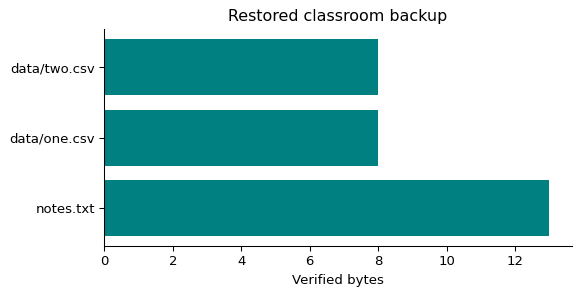

In [2]:
fixture = {
    "notes.txt": b"release notes",
    "data/one.csv": b"x,y\n1,2\n",
    "data/two.csv": b"x,y\n3,4\n",
}
expected = {k: sha256(v).hexdigest() for k, v in fixture.items()}
with TemporaryDirectory() as work:
    root = Path(work)
    archive = root / "snapshot.zip"
    dest = root / "restored"
    with ZipFile(archive, "w") as z:
        for k, v in fixture.items():
            z.writestr(k, v)
    with ZipFile(archive) as z:
        for k in expected:
            out = dest / k
            out.parent.mkdir(parents=True, exist_ok=True)
            out.write_bytes(z.read(k))
    valid = {
        k: (dest / k).is_file() and sha256((dest / k).read_bytes()).hexdigest() == digest
        for k, digest in expected.items()
    }
print("verified objects", sum(valid.values()), "of", len(expected))
print("verified bytes", sum(len(fixture[k]) for k, v in valid.items() if v))
assert all(valid.values())
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.barh(list(fixture), [len(v) for v in fixture.values()], color="teal")
ax.set(xlabel="Verified bytes", title="Restored classroom backup")
plt.show()

## Interpreting the result

A byte-perfect restore checks integrity for this snapshot. Application consistency and restore time require separate tests on a representative workload.

## Exercise

Exclude one expected item from the restore and add an explicit missing-object outcome.

## References

[NIST Cybersecurity Framework 2.0](https://doi.org/10.6028/NIST.CSWP.29)

[Python, hashlib](https://docs.python.org/3/library/hashlib.html)